# Lesotho POI data: GNN node classification

**Input:** `poi_engineered.csv` (6,083 nodes, 66 features with the prefixes `loc_`, `adm_`, `struct_`, `attr_`,
`ctx_`, plus the carried-over id, label, graph and split columns).
**Output:** `model_outputs/` (per-fold metrics, out-of-fold predictions, predictions for the 131 unlabelled nodes,
trained weights) and `model_outputs/training_progress.log`, which a separate terminal window follows live.

**Task.** Semi-supervised, transductive node classification: every POI is a node of the k = 8 nearest-neighbour graph,
and the model predicts its category (8 classes) from its own features and its neighbourhood.

**Design choices, taken from the summary of `poi_engineered_vis.ipynb`.**

| Finding there | What this notebook does |
|---|---|
| Averaging over neighbours wipes out the node's own `attr_` signal (Section 5) | No plain GCN. Every layer keeps a separate path for the node itself: GraphSAGE with a root weight, or GAT, both with residual connections and jumping knowledge over all layers |
| Standardised rare district one-hots dominate the feature space (Section 6) | Only the continuous features are standardised; the 16 binary indicators stay 0/1 (tested as an ablation) |
| Retail, Food & Beverage and Other share one profile; the graph helps for Retail, Tourism and Other (Sections 2, 6) | Label-aware message passing: training labels are fed as inputs (the "label trick"), so neighbours' known categories can be used, computed inside each training fold only |
| Weak Healthcare, harder urban fold 4 (Sections 6, 7) | Class-weighted loss; per-class and per-fold scores reported next to the mean macro-F1 |
| `attr_osm_id_rank` acts as a mapping-session identifier (Section 8) | Results with and without the three `osm_id_rank` columns |
| Shape, structure and district features are weak alone but not redundant (Sections 2, 4) | Feature-group ablations |

**Protocol.** Spatial 5-fold CV on the 5 km blocks (`fold`). For test fold *f*, fold *(f + 1) mod 5* is the
validation fold (early stopping and model selection) and the other three folds train the model. Test labels are never
used for any choice. GraphSAGE and GAT are compared under the same protocol, the better one is tuned on the
validation folds, and the final model is a seed ensemble.

In [1]:
import copy
import itertools
import json
import subprocess
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.spatial import cKDTree
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm notice from a PyG import
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
import torch
import torch.nn as nn
import torch.nn.functional as Fn
from torch_geometric.nn import GATv2Conv, SAGEConv
from torch_geometric.utils import contains_isolated_nodes, contains_self_loops, is_undirected, to_undirected

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

IN_CSV = "poi_engineered.csv"
OUT_DIR = Path("model_outputs")
OUT_DIR.mkdir(exist_ok=True)
LOG_PATH = OUT_DIR / "training_progress.log"
FEAT_RE = r"^(loc|adm|struct|attr|ctx)_"
K = 8               # k-NN graph used by the EDA, the structural encodings and the model
SEED = 42
N_FOLDS = 5
torch.set_num_threads(4)

# Chart styling (same as the earlier notebooks)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5",
                                                     "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "figure.dpi": 100, "legend.frameon": False,
})


def log(msg):
    """Append a timestamped line to the progress log (ASCII only, so any terminal shows it cleanly)."""
    line = f"{time.strftime('%H:%M:%S')}  {msg}"
    with open(LOG_PATH, "a", encoding="ascii", errors="replace") as fh:
        fh.write(line + "\n")


# Live progress: a separate terminal window follows the log while the model trains (Windows only; opened once)
OPEN_PROGRESS_WINDOW = True
LOG_PATH.write_text("", encoding="ascii")
log("GNN training progress log - model.ipynb")
if OPEN_PROGRESS_WINDOW and sys.platform == "win32" and not globals().get("_progress_window_opened"):
    subprocess.Popen(
        ["powershell", "-NoExit", "-Command",
         f"$host.UI.RawUI.WindowTitle = 'GNN training progress'; "
         f"Get-Content -LiteralPath '{LOG_PATH.resolve()}' -Wait -Tail 60"],
        creationflags=subprocess.CREATE_NEW_CONSOLE)
    _progress_window_opened = True

df = pd.read_csv(IN_CSV, keep_default_na=False, na_values=[""])
FEATS = df.filter(regex=FEAT_RE).columns.tolist()
N = len(df)
assert df["node_id"].tolist() == list(range(N))
assert np.isfinite(df[FEATS].to_numpy(float)).all()
labelled = df["is_labelled"].eq(1).to_numpy()
y_np = df["label"].to_numpy()
fold_np = df["fold"].to_numpy()
CATS = df.loc[labelled].sort_values("label")["category"].unique().tolist()   # label order 0..7
C = len(CATS)

print(f"torch {torch.__version__} | CPU threads {torch.get_num_threads()} | progress log: {LOG_PATH.resolve()}")
print(f"{N:,} nodes x {df.shape[1]} columns | {len(FEATS)} features | labelled {labelled.sum():,} | "
      f"unlabelled {(~labelled).sum()}")
print("Classes (label order):", CATS)
print(pd.crosstab(df.loc[labelled, "category"], df.loc[labelled, "fold"], margins=True).loc[CATS + ["All"]])

torch 2.14.0+cpu | CPU threads 4 | progress log: C:\Users\BrainTech\Documents\DevDox\research\poi_business\POIs\model_outputs\training_progress.log
6,083 nodes x 92 columns | 66 features | labelled 5,952 | unlabelled 131
Classes (label order): ['Infrastructure', 'Educational', 'Retail', 'Other', 'Food & Beverage', 'Tourism', 'Religious', 'Healthcare']
fold                0     1     2     3     4   All
category                                           
Infrastructure    362   367   349   354   360  1792
Educational       353   341   339   389   244  1666
Retail            191   232   251   217   290  1181
Other              63    61    70    60    80   334
Food & Beverage    67    66    40    48    72   293
Tourism            59    45    47    55    46   252
Religious          42    47    57    53    37   236
Healthcare         45    39    30    32    52   198
All              1182  1198  1183  1208  1181  5952


## 1. Graph, features and spatial CV splits

- **Edges:** k = 8 nearest neighbours from `x_km`/`y_km`, made undirected and with self excluded explicitly: the same
  graph the `struct_` features were computed on (feature notebook, Section 12).
- **Features:** the 66 prefixed columns. The binary columns (0/1 only) are kept as 0/1; the continuous columns are
  standardised with a mean and SD fitted on the non-test folds of each split only (no labels are involved, and the
  test fold's rows never enter the fit).
- **Splits:** test fold *f*, validation fold *(f + 1) mod 5*, the other three folds train. Only labelled nodes enter
  the masks; the 131 unlabelled nodes stay in the graph as neighbours.

In [2]:
# k = 8 nearest-neighbour graph (identical to the one the struct_ features describe)
xy = df[["x_km", "y_km"]].to_numpy() * 1000
_, nn_i = cKDTree(xy).query(xy, k=K + 2)
nn_i = nn_i[nn_i != np.arange(N)[:, None]].reshape(N, K + 1)[:, :K]      # drop self explicitly
EDGE_INDEX = to_undirected(torch.tensor(np.vstack([np.repeat(np.arange(N), K), nn_i.ravel()])), num_nodes=N)
assert is_undirected(EDGE_INDEX) and not contains_self_loops(EDGE_INDEX)
assert not contains_isolated_nodes(EDGE_INDEX, N)
deg = np.bincount(EDGE_INDEX[0].numpy(), minlength=N)

# Binary indicators stay 0/1; continuous features are standardised per split
X_ALL = df[FEATS].to_numpy(np.float64)
BINARY = [c for c in FEATS if set(np.unique(df[c])) <= {0, 1}]
OSM_RANK = [c for c in FEATS if "osm_id_rank" in c]
GROUPS = ["loc", "adm", "struct", "attr", "ctx"]


def make_x(feats, test_fold, scale_binary=False):
    """Feature matrix for one split: standardise with the non-test folds' rows only."""
    X = df[feats].to_numpy(np.float64).copy()
    fit_rows = fold_np != test_fold
    cols = [j for j, c in enumerate(feats) if scale_binary or c not in BINARY]
    mu, sd = X[fit_rows][:, cols].mean(0), X[fit_rows][:, cols].std(0)
    sd[sd == 0] = 1.0
    X[:, cols] = (X[:, cols] - mu) / sd
    return torch.tensor(X, dtype=torch.float32)


def make_split(test_fold):
    """Boolean masks over nodes (labelled only): train on 3 folds, validate on the next fold, test on test_fold."""
    val_fold = (test_fold + 1) % N_FOLDS
    train = labelled & (fold_np != test_fold) & (fold_np != val_fold)
    val = labelled & (fold_np == val_fold)
    test = labelled & (fold_np == test_fold)
    return {"test_fold": test_fold, "val_fold": val_fold, "train": torch.tensor(train),
            "val": torch.tensor(val), "test": torch.tensor(test)}


SPLITS = [make_split(f) for f in range(N_FOLDS)]
Y = torch.tensor(np.where(labelled, y_np, 0))          # unlabelled nodes get a dummy 0; they are in no mask

print(f"Graph: {N:,} nodes, {EDGE_INDEX.size(1) // 2:,} undirected edges, degree {deg.min()} to {deg.max()} "
      f"(median {int(np.median(deg))})")
same = (y_np[EDGE_INDEX[0]] == y_np[EDGE_INDEX[1]]) & labelled[EDGE_INDEX[0]] & labelled[EDGE_INDEX[1]]
both = labelled[EDGE_INDEX[0]] & labelled[EDGE_INDEX[1]]
print(f"Edge homophily (labelled pairs): {same.sum() / both.sum():.1%}")
print(f"Features: {len(FEATS)} = {len(FEATS) - len(BINARY)} continuous (standardised) + {len(BINARY)} binary (0/1)")
print("Binary:", BINARY)
print("osm_id_rank columns:", OSM_RANK)
print(pd.DataFrame([{"test fold": s["test_fold"], "val fold": s["val_fold"], "train": int(s["train"].sum()),
                     "val": int(s["val"].sum()), "test": int(s["test"].sum())} for s in SPLITS]).to_string(index=False))
x0 = make_x(FEATS, 0)
assert torch.isfinite(x0).all()
print(f"Split 0 check: continuous columns on the non-test rows have mean "
      f"{x0[torch.tensor(fold_np != 0)][:, [FEATS.index(c) for c in FEATS if c not in BINARY]].mean():.1e}")

Graph: 6,083 nodes, 31,452 undirected edges, degree 8 to 20 (median 10)
Edge homophily (labelled pairs): 37.5%
Features: 66 = 50 continuous (standardised) + 16 binary (0/1)
Binary: ['loc_is_urban', 'adm_district_LSA', 'adm_district_LSB', 'adm_district_LSC', 'adm_district_LSD', 'adm_district_LSE', 'adm_district_LSF', 'adm_district_LSG', 'adm_district_LSH', 'adm_district_LSJ', 'adm_district_LSK', 'attr_has_name', 'attr_has_address', 'attr_has_hours', 'attr_has_footprint', 'attr_is_point']
osm_id_rank columns: ['attr_osm_id_rank', 'ctx_osm_id_rank_mean_k32', 'ctx_osm_id_rank_std_k32', 'ctx_osm_id_rank_vs_k32']
 test fold  val fold  train  val  test
         0         1   3572 1198  1182
         1         2   3571 1183  1198
         2         3   3561 1208  1183
         3         4   3563 1181  1208
         4         0   3589 1182  1181
Split 0 check: continuous columns on the non-test rows have mean 1.0e-09


## 2. The model and the training loop

**Architecture** (the same skeleton for both layer types, so the comparison isolates the message-passing layer):

1. **Encoder:** a linear layer maps the node's features (and, with the label trick, its visible label) to a hidden
   vector `h0`.
2. **Message passing:** L layers of either **GraphSAGE** (mean of the neighbours plus a separate root weight for the
   node) or **GATv2** (attention weights over the neighbours, several heads). Each layer is followed by batch norm,
   ReLU and dropout, and is **residual** (`h_l = h_{l-1} + layer(h_{l-1})`), so the node's own signal is never
   averaged away.
3. **Jumping knowledge:** the classifier reads the concatenation `[h0, h1, ..., hL]`, so it can weigh the node's own
   encoding against its 1-hop and 2-hop context per class.

**Label trick** (optional, tested below). Neighbour categories are informative for Retail, Tourism and Other
(vis notebook, Section 6), but they are labels, so they must come from the training folds only. The node input gets
8 extra columns: the one-hot category of a node whose label is visible, zeros otherwise. In each epoch a random half of
the training nodes shows its label and the loss is taken on the other half, so the model can never read a node's own
answer. At evaluation all training labels are visible; validation, test and unlabelled nodes never are.

**Training:** full-batch AdamW, cross-entropy with class weights `(n / (8 * n_c)) ** power` from the training nodes and
light label smoothing, early stopping on validation macro-F1 with the best epoch's weights restored. Each run writes
its progress to `model_outputs/training_progress.log`.

In [9]:
class FastDropout(nn.Module):
    """Inverted dropout with a rand() mask: same maths as nn.Dropout, about twice as fast on CPU."""

    def __init__(self, p):
        super().__init__()
        self.p = p

    def forward(self, x):
        if not self.training or self.p == 0:
            return x
        return x * (torch.rand_like(x) >= self.p) / (1 - self.p)


class GNN(nn.Module):
    """Encoder -> L residual message-passing layers (GraphSAGE or GATv2) -> jumping-knowledge classifier."""

    def __init__(self, in_dim, n_classes, conv="sage", hidden=128, layers=2, heads=4, dropout=0.3,
                 input_dropout=0.1, attn_dropout=0.1, label_input=False):
        super().__init__()
        self.label_input, self.n_classes = label_input, n_classes
        self.in_drop, self.drop = FastDropout(input_dropout), FastDropout(dropout)
        self.enc = nn.Linear(in_dim + (n_classes if label_input else 0), hidden)
        self.enc_norm = nn.BatchNorm1d(hidden)
        self.convs, self.norms = nn.ModuleList(), nn.ModuleList()
        for _ in range(layers):
            if conv == "sage":
                self.convs.append(SAGEConv(hidden, hidden, aggr="mean", root_weight=True))
            elif conv == "gat":
                self.convs.append(GATv2Conv(hidden, hidden // heads, heads=heads, concat=True,
                                            dropout=attn_dropout, add_self_loops=True))
            else:
                raise ValueError(conv)
            self.norms.append(nn.BatchNorm1d(hidden))
        self.head = nn.Linear(hidden * (layers + 1), n_classes)

    def forward(self, x, edge_index, label_onehot=None):
        if self.label_input:
            x = torch.cat([x, label_onehot], dim=1)
        h = self.drop(Fn.relu(self.enc_norm(self.enc(self.in_drop(x)))))
        hs = [h]
        for conv, norm in zip(self.convs, self.norms):
            h = h + self.drop(Fn.relu(norm(conv(h, edge_index))))
            hs.append(h)
        return self.head(torch.cat(hs, dim=1))


BASE_CFG = dict(conv="sage", hidden=128, layers=2, heads=4, dropout=0.3, input_dropout=0.1, attn_dropout=0.1,
                label_input=False, label_rate=0.5, lr=5e-3, weight_decay=5e-4, cw_power=0.5, smoothing=0.05,
                max_epochs=300, patience=50, scale_binary=False)


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=list(range(C)), zero_division=0)


def label_features(visible_mask):
    """One-hot categories of the nodes whose label is visible; zeros elsewhere."""
    oh = torch.zeros(N, C)
    idx = visible_mask.nonzero().squeeze(1)
    oh[idx, Y[idx]] = 1.0
    return oh


def train_one(cfg, x, split, seed, tag=""):
    """Train one model on one split. Returns the best-epoch softmax over all nodes and a record of the run."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = GNN(x.size(1), C, conv=cfg["conv"], hidden=cfg["hidden"], layers=cfg["layers"], heads=cfg["heads"],
                dropout=cfg["dropout"], input_dropout=cfg["input_dropout"], attn_dropout=cfg["attn_dropout"],
                label_input=cfg["label_input"])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    tr_idx = split["train"].nonzero().squeeze(1)
    counts = torch.bincount(Y[tr_idx], minlength=C).float()
    weight = (len(tr_idx) / (C * counts)) ** cfg["cw_power"]
    y_val = Y[split["val"]].numpy()
    eval_labels = label_features(split["train"]) if cfg["label_input"] else None

    best = {"f1": -1.0, "epoch": 0, "state": None}
    t0 = time.time()
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        opt.zero_grad()
        if cfg["label_input"]:
            perm = tr_idx[torch.randperm(len(tr_idx), generator=gen)]
            n_vis = int(cfg["label_rate"] * len(perm))
            vis = torch.zeros(N, dtype=torch.bool)
            vis[perm[:n_vis]] = True
            loss_idx, lab_in = perm[n_vis:], label_features(vis)
        else:
            loss_idx, lab_in = tr_idx, None
        out = model(x, EDGE_INDEX, lab_in)
        loss = Fn.cross_entropy(out[loss_idx], Y[loss_idx], weight=weight, label_smoothing=cfg["smoothing"])
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            pred = model(x, EDGE_INDEX, eval_labels).argmax(1)
        f1_val = macro_f1(y_val, pred[split["val"]].numpy())
        if f1_val > best["f1"]:
            best = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        if epoch % 25 == 0:
            f1_tr = macro_f1(Y[tr_idx].numpy(), pred[tr_idx].numpy())
            log(f"  {tag} fold {split['test_fold']} seed {seed} | ep {epoch:3d} | loss {loss.item():.3f} | "
                f"train F1 {f1_tr:.3f} | val F1 {f1_val:.3f} | best {best['f1']:.3f} @ {best['epoch']}")
        if epoch - best["epoch"] >= cfg["patience"]:
            break

    model.load_state_dict(best["state"])
    model.eval()
    with torch.no_grad():
        prob = Fn.softmax(model(x, EDGE_INDEX, eval_labels), dim=1)
    secs = time.time() - t0
    log(f"  {tag} fold {split['test_fold']} seed {seed} done | best val F1 {best['f1']:.3f} at epoch "
        f"{best['epoch']} | {epoch} epochs in {secs:.0f}s")
    return prob, {"val_f1": best["f1"], "best_epoch": best["epoch"], "epochs": epoch, "secs": secs,
                  "model": model}


def run_cv(cfg, feats=FEATS, seeds=(0, 1, 2), tag="run", folds=range(N_FOLDS), keep_models=False):
    """Spatial CV. Test predictions of each fold are the mean softmax over the seeds (a seed ensemble)."""
    cfg = {**BASE_CFG, **cfg}
    log(f"=== {tag}: {json.dumps({k: v for k, v in cfg.items() if BASE_CFG.get(k) != v or k == 'conv'})} | "
        f"{len(feats)} features | seeds {list(seeds)}")
    oof = np.full((N, C), np.nan)
    probs_all, rows, models = [], [], []
    t0 = time.time()
    for f in folds:
        split = SPLITS[f]
        x = make_x(feats, f, scale_binary=cfg["scale_binary"])
        fold_probs = []
        for s in seeds:
            prob, rec = train_one(cfg, x, split, SEED + 1000 * s + f, tag=tag)
            fold_probs.append(prob.numpy())
            te = split["test"].numpy()
            rows.append({"fold": f, "seed": s, "val_f1": rec["val_f1"], "best_epoch": rec["best_epoch"],
                         "test_f1_single": macro_f1(y_np[te], prob.numpy()[te].argmax(1)), "secs": rec["secs"]})
            if keep_models:
                models.append((f, s, rec["model"]))
        p = np.mean(fold_probs, axis=0)
        te = split["test"].numpy()
        oof[te] = p[te]
        probs_all.append(p)
        f1_te = macro_f1(y_np[te], p[te].argmax(1))
        log(f"  {tag} fold {f}: ensemble test macro-F1 {f1_te:.3f} | acc {(p[te].argmax(1) == y_np[te]).mean():.3f}")
    runs = pd.DataFrame(rows)
    fold_f1 = {f: macro_f1(y_np[SPLITS[f]["test"].numpy()], oof[SPLITS[f]["test"].numpy()].argmax(1)) for f in folds}
    res = {"tag": tag, "cfg": cfg, "runs": runs, "oof": oof, "probs": probs_all, "fold_f1": fold_f1,
           "val_f1": runs["val_f1"].mean(), "test_f1": float(np.mean(list(fold_f1.values()))),
           "test_f1_sd": float(np.std(list(fold_f1.values()))), "minutes": (time.time() - t0) / 60,
           "models": models}
    log(f"=== {tag} finished: val F1 {res['val_f1']:.3f} | test macro-F1 {res['test_f1']:.3f} "
        f"+/- {res['test_f1_sd']:.3f} | {res['minutes']:.1f} min")
    return res


# Smoke test: one short run per layer type on fold 0, to check shapes and timing
for conv in ["sage", "gat"]:
    t = time.time()
    r = run_cv({"conv": conv, "max_epochs": 30, "patience": 30}, seeds=(0,), folds=[0], tag=f"smoke-{conv}")
    n_par = sum(p.numel() for p in GNN(len(FEATS), C, conv=conv).parameters())
    print(f"{conv}: {n_par:,} parameters | 30 epochs in {time.time() - t:.1f}s | "
          f"val F1 {r['val_f1']:.3f} | test F1 {r['test_f1']:.3f}")

sage: 78,216 parameters | 30 epochs in 3.4s | val F1 0.362 | test F1 0.349
gat: 78,984 parameters | 30 epochs in 8.9s | val F1 0.361 | test F1 0.336


## 3. GraphSAGE or GAT?

Both layer types run in the same skeleton with the same starting hyperparameters (hidden 128, 2 layers, dropout 0.3,
AdamW 5e-3), all 66 features, 3 seeds per fold, with and without the label trick. The choice is made on the
**validation** macro-F1 (mean over the 15 runs); the test scores are shown but play no part in it.

In [11]:
RESULTS = {}      # every CV run of the notebook, by tag


def summarise(tags):
    """One row per CV run: validation F1 (selection criterion), test macro-F1 per fold and its mean."""
    rows = []
    for t in tags:
        r = RESULTS[t]
        rows.append({"run": t, "val F1": r["val_f1"], **{f"test f{f}": v for f, v in r["fold_f1"].items()},
                     "test F1": r["test_f1"], "test SD": r["test_f1_sd"],
                     "test acc": (r["oof"][labelled].argmax(1) == y_np[labelled]).mean(),
                     "epochs": r["runs"]["best_epoch"].median(), "min": r["minutes"]})
    return pd.DataFrame(rows).set_index("run").round(3)


for conv, lt in itertools.product(["sage", "gat"], [False, True]):
    tag = f"{conv}{'+labels' if lt else ''}"
    RESULTS[tag] = run_cv({"conv": conv, "label_input": lt}, tag=tag)

cmp_tags = ["sage", "sage+labels", "gat", "gat+labels"]
print(summarise(cmp_tags).to_string())

             val F1  test f0  test f1  test f2  test f3  test f4  test F1  test SD  test acc  epochs     min
run                                                                                                         
sage          0.382    0.377    0.372    0.415    0.387    0.339    0.378    0.025     0.605    53.0   3.470
sage+labels   0.391    0.366    0.378    0.391    0.363    0.322    0.364    0.023     0.601    66.0   3.616
gat           0.370    0.373    0.371    0.387    0.370    0.293    0.359    0.033     0.596    61.0  12.676
gat+labels    0.379    0.368    0.374    0.392    0.347    0.310    0.358    0.028     0.596    65.0  12.266


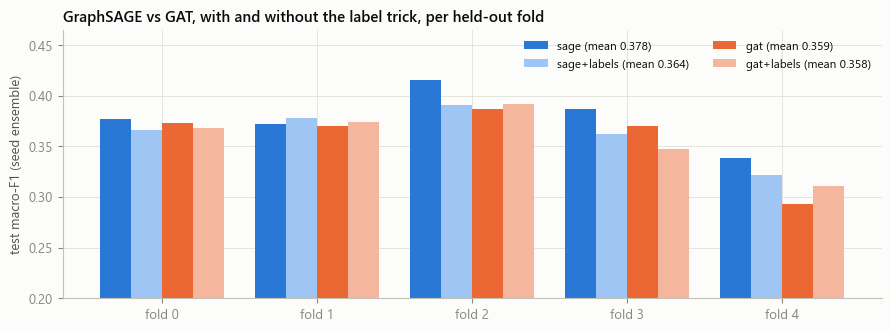

Selected by validation F1: sage+labels (val 0.391); time per CV run: sage 3.5 min, sage+labels 3.6 min, gat 12.7 min, gat+labels 12.3 min


In [12]:
cmp = summarise(cmp_tags)
BEST_TAG = cmp["val F1"].idxmax()
BEST_BASE = {**BASE_CFG, "conv": RESULTS[BEST_TAG]["cfg"]["conv"], "label_input": RESULTS[BEST_TAG]["cfg"]["label_input"]}
TUNE_SEEDS = (0, 1, 2) if BEST_BASE["conv"] == "sage" else (0, 1)      # GAT is ~3.5x slower per epoch

fig, ax = plt.subplots(figsize=(9, 3.4))
w = 0.2
for i, t in enumerate(cmp_tags):
    vals = [RESULTS[t]["fold_f1"][f] for f in range(N_FOLDS)]
    ax.bar(np.arange(N_FOLDS) + (i - 1.5) * w, vals, w, label=f"{t} (mean {np.mean(vals):.3f})",
           color=[BLUE, "#9ec5f4", ORANGE, "#f4b69c"][i])
ax.set_xticks(range(N_FOLDS), [f"fold {f}" for f in range(N_FOLDS)])
ax.set_ylabel("test macro-F1 (seed ensemble)")
ax.set_ylim(0.2, max(cmp[[f"test f{f}" for f in range(N_FOLDS)]].max()) + 0.05)
ax.set_title("GraphSAGE vs GAT, with and without the label trick, per held-out fold")
ax.legend(ncol=2, fontsize=8.5, loc="upper right")
plt.tight_layout()
plt.show()

print(f"Selected by validation F1: {BEST_TAG} (val {cmp.loc[BEST_TAG, 'val F1']:.3f}); "
      f"time per CV run: " + ", ".join(f"{t} {RESULTS[t]['minutes']:.1f} min" for t in cmp_tags))
log(f"Architecture selected on validation F1: {BEST_TAG}")

**Findings.**

- **GraphSAGE beats GAT** on validation (0.382 against 0.370 without the label trick, 0.391 against 0.379 with it)
  and on test (0.378 against 0.359), and it trains about 3.5 times faster (3.5 against 12.7 minutes per CV run). The
  attention weights do not pay off here: the k-NN neighbours of a node are mostly similar to each other (median
  feature smoothness r = 0.97 in the vis notebook), so there is little for attention to choose between, and the
  extra parameters overfit faster. **GraphSAGE is the model carried forward.**
- **Fold 4, the urban fold, is the hardest for all four models** (accuracy about 0.44 against 0.63 elsewhere), as the
  vis notebook expected: it holds most of Maseru, so it is tested on the densest commercial area with fewer urban
  training examples.
- **The label trick raises validation F1 slightly (+0.009 for both layer types) but not test F1 (-0.014 for
  GraphSAGE).** The differences are within one fold's SD (about 0.025), so neither version is clearly better. Under
  spatial CV few test nodes have labelled neighbours (77% of edges stay inside a fold), which limits what neighbour
  labels can add. The protocol selects on validation, so `sage+labels` goes on to tuning. The ablations in Section 6
  report the version without it under the tuned settings, so the choice can be checked.

## 4. Tuning the selected model

A random search of 12 configurations drawn from the grid below (width, depth, dropout, learning rate, weight decay,
class-weight strength and, with the label trick, the share of training labels shown as inputs). Each configuration
runs the full 5-split spatial CV with 3 seeds; the ranking uses validation macro-F1 only. The untuned configuration
from Section 3 competes as well.

In [13]:
SEARCH_SPACE = {
    "hidden": [64, 128, 256],
    "layers": [1, 2, 3],
    "dropout": [0.2, 0.3, 0.5],
    "input_dropout": [0.0, 0.1, 0.2],
    "lr": [2e-3, 5e-3, 1e-2],
    "weight_decay": [5e-4, 5e-3, 5e-2],
    "cw_power": [0.5, 0.75, 1.0],
}
if BEST_BASE["label_input"]:
    SEARCH_SPACE["label_rate"] = [0.3, 0.5, 0.7]
N_TRIALS = 12

rng = np.random.default_rng(SEED)
trials, seen = [], set()
while len(trials) < N_TRIALS:
    cand = {k: v[rng.integers(len(v))] for k, v in SEARCH_SPACE.items()}
    key = tuple(sorted(cand.items()))
    if key not in seen:
        seen.add(key)
        trials.append(cand)

tune_tags = [BEST_TAG]
for i, cand in enumerate(trials):
    tag = f"tune{i:02d}"
    log(f"--- tuning trial {i + 1}/{N_TRIALS}")
    RESULTS[tag] = run_cv({**BEST_BASE, **cand}, tag=tag, seeds=TUNE_SEEDS)
    tune_tags.append(tag)

tune_table = summarise(tune_tags)
tune_table.insert(0, "config", [json.dumps({k: RESULTS[t]["cfg"][k] for k in SEARCH_SPACE}) for t in tune_tags])
tune_table = tune_table.sort_values("val F1", ascending=False)
with pd.option_context("display.max_colwidth", 200):
    print(tune_table.to_string())
BEST_TUNED = tune_table.index[0]
BEST_CFG = {**BEST_BASE, **{k: RESULTS[BEST_TUNED]["cfg"][k] for k in SEARCH_SPACE}}
print(f"\nSelected by validation F1: {BEST_TUNED} -> {json.dumps(BEST_CFG)}")

                                                                                                                                                   config  val F1  test f0  test f1  test f2  test f3  test f4  test F1  test SD  test acc  epochs     min
run                                                                                                                                                                                                                                                       
tune04            {"hidden": 64, "layers": 2, "dropout": 0.5, "input_dropout": 0.0, "lr": 0.01, "weight_decay": 0.05, "cw_power": 0.5, "label_rate": 0.5}   0.395    0.352    0.373    0.406    0.369    0.338    0.367    0.023     0.606    84.0   2.682
sage+labels   {"hidden": 128, "layers": 2, "dropout": 0.3, "input_dropout": 0.1, "lr": 0.005, "weight_decay": 0.0005, "cw_power": 0.5, "label_rate": 0.5}   0.391    0.366    0.378    0.391    0.363    0.322    0.364    0.023     0.601    66.0   3.

**Findings.**

- **Selected: `tune04`**: GraphSAGE, hidden 64, 2 layers, dropout 0.5, learning rate 0.01, weight decay 0.05,
  class-weight power 0.5, label trick with half the training labels visible (validation F1 0.395 against 0.391 for
  the untuned configuration).
- **The model is not sensitive to its hyperparameters.** Across the 13 configurations validation F1 spans 0.358 to
  0.395 and test F1 0.342 to 0.368, and the top six differ by less than one fold's SD. Tuning moves the result by about
  0.01; the limit is the information in the features and the graph, not the settings.
- **The one consistent effect is class weighting.** All three configurations with full "balanced" weights
  (power 1.0) rank last on validation, with the lowest accuracy (0.50 to 0.52): they buy recall on the small classes
  with too many false positives. Power 0.5 (square-root weights) is in all four best configurations.
- Wider (256) and deeper (3-layer) models are no better and take 3 to 6 times longer. A strongly regularised small
  model (64 units, dropout 0.5, weight decay 0.05) is best, as expected with about 3,600 training nodes per split.

## 5. Final model: seed ensemble and class calibration

The selected configuration is retrained with 5 seeds per split; each test fold is predicted by the mean softmax of
its 5 models.

**Calibration for macro-F1.** The class-weighted loss makes the model trade precision for recall on the small
classes, but not necessarily at the point that maximises macro-F1. For each split, one additive offset per class is
fitted on the log-probabilities of that split's **validation** fold (coordinate ascent on a grid from -2 to 2) and then
applied unchanged to its test fold. This step was fixed before any test score was seen, and the uncalibrated scores
are reported next to the calibrated ones.

In [14]:
OFFSET_GRID = np.linspace(-2, 2, 41)


def fit_offsets(logp, y_true, rounds=3):
    """Per-class additive offsets on log-probabilities that maximise macro-F1 (coordinate ascent on a grid)."""
    b = np.zeros(C)
    best = macro_f1(y_true, (logp + b).argmax(1))
    for _ in range(rounds):
        for c in range(C):
            for v in OFFSET_GRID:
                trial = b.copy()
                trial[c] = v
                s = macro_f1(y_true, (logp + trial).argmax(1))
                if s > best + 1e-9:
                    best, b = s, trial
    return b


def calibrate(res):
    """Fit offsets on each split's validation fold, apply them to its test fold. Test labels are not used."""
    oof_cal = np.full(N, -1)
    offsets = {}
    for f in range(N_FOLDS):
        sp = SPLITS[f]
        logp = np.log(res["probs"][f] + 1e-9)
        va, te = sp["val"].numpy(), sp["test"].numpy()
        offsets[f] = fit_offsets(logp[va], y_np[va])
        oof_cal[te] = (logp[te] + offsets[f]).argmax(1)
    fold_f1 = {f: macro_f1(y_np[SPLITS[f]["test"].numpy()], oof_cal[SPLITS[f]["test"].numpy()]) for f in range(N_FOLDS)}
    return oof_cal, offsets, fold_f1


FINAL_SEEDS = (0, 1, 2, 3, 4)
RESULTS["final"] = FINAL = run_cv(BEST_CFG, tag="final", seeds=FINAL_SEEDS, keep_models=True)
oof_raw = FINAL["oof"].argmax(1)
oof_cal, OFFSETS, fold_f1_cal = calibrate(FINAL)
FINAL["oof_cal"], FINAL["offsets"], FINAL["fold_f1_cal"] = oof_cal, OFFSETS, fold_f1_cal

tbl = pd.DataFrame({
    "test nodes": [int(SPLITS[f]["test"].sum()) for f in range(N_FOLDS)],
    "macro-F1 raw": [FINAL["fold_f1"][f] for f in range(N_FOLDS)],
    "macro-F1 calibrated": [fold_f1_cal[f] for f in range(N_FOLDS)],
    "accuracy calibrated": [(oof_cal[SPLITS[f]["test"].numpy()] == y_np[SPLITS[f]["test"].numpy()]).mean()
                            for f in range(N_FOLDS)],
}, index=pd.Index(range(N_FOLDS), name="test fold"))
tbl.loc["mean"] = tbl.mean()
tbl.loc["SD"] = tbl.iloc[:N_FOLDS].std(ddof=0)
print(tbl.round(3).to_string())
print(f"\nPooled over all {labelled.sum():,} labelled nodes (each predicted once, by the fold that held it out): "
      f"macro-F1 raw {macro_f1(y_np[labelled], oof_raw[labelled]):.3f}, "
      f"calibrated {macro_f1(y_np[labelled], oof_cal[labelled]):.3f}; "
      f"accuracy calibrated {(oof_cal[labelled] == y_np[labelled]).mean():.3f}")
print("\nClass offsets fitted on each validation fold (added to log-probabilities):")
print(pd.DataFrame(OFFSETS, index=CATS).T.round(2).rename_axis("test fold").to_string())
log(f"Final model: raw test macro-F1 {tbl.loc['mean', 'macro-F1 raw']:.3f}, calibrated "
    f"{tbl.loc['mean', 'macro-F1 calibrated']:.3f}")

           test nodes  macro-F1 raw  macro-F1 calibrated  accuracy calibrated
test fold                                                                    
0            1182.000         0.390                0.399                0.604
1            1198.000         0.362                0.395                0.643
2            1183.000         0.406                0.393                0.608
3            1208.000         0.367                0.363                0.654
4            1181.000         0.348                0.311                0.395
mean         1190.400         0.375                0.372                0.581
SD             10.781         0.021                0.033                0.095

Pooled over all 5,952 labelled nodes (each predicted once, by the fold that held it out): macro-F1 raw 0.379, calibrated 0.379; accuracy calibrated 0.581

Class offsets fitted on each validation fold (added to log-probabilities):
           Infrastructure  Educational  Retail  Other  Food & Bever

### Per-class results

Out-of-fold: every labelled node is predicted once, by the ensemble whose split held its fold out.

                 precision  recall     F1  support  F1 raw  F1 fold min  F1 fold max
Infrastructure       0.712   0.757  0.734     1792   0.755        0.635        0.785
Educational          0.871   0.831  0.850     1666   0.867        0.775        0.884
Retail               0.494   0.356  0.414     1181   0.479        0.188        0.514
Other                0.171   0.099  0.125      334   0.157        0.081        0.180
Food & Beverage      0.150   0.273  0.194      293   0.127        0.066        0.313
Tourism              0.236   0.258  0.246      252   0.235        0.161        0.315
Religious            0.317   0.347  0.331      236   0.323        0.250        0.400
Healthcare           0.105   0.182  0.133      198   0.092        0.095        0.213


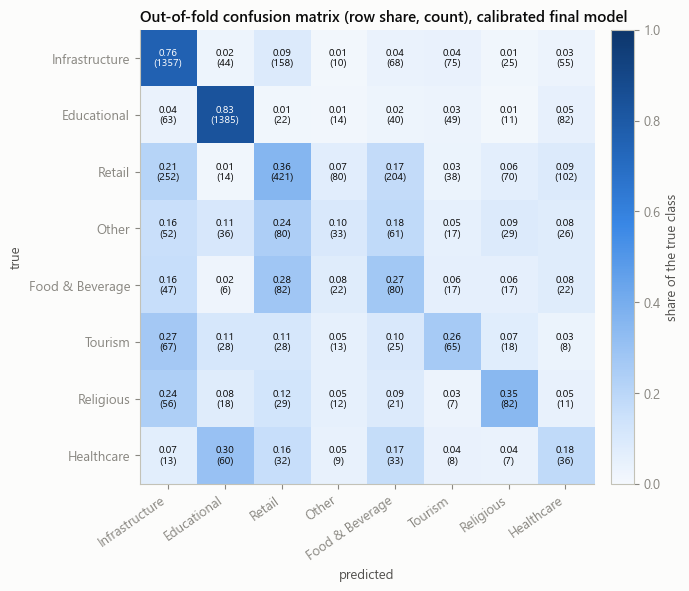

In [15]:
yt, yp = y_np[labelled], oof_cal[labelled]
prec, rec, f1c, sup = precision_recall_fscore_support(yt, yp, labels=list(range(C)), zero_division=0)
per_class = pd.DataFrame({"precision": prec, "recall": rec, "F1": f1c, "support": sup}, index=CATS)
per_class["F1 raw"] = precision_recall_fscore_support(yt, oof_raw[labelled], labels=list(range(C)),
                                                      zero_division=0)[2]
f1_fold = np.array([precision_recall_fscore_support(y_np[m], oof_cal[m], labels=list(range(C)), zero_division=0)[2]
                    for m in (SPLITS[f]["test"].numpy() for f in range(N_FOLDS))])      # folds x classes
per_class["F1 fold min"], per_class["F1 fold max"] = f1_fold.min(0), f1_fold.max(0)
print(per_class.round(3).to_string())

cm = confusion_matrix(yt, yp, labels=list(range(C)))
cm_row = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(cm_row, cmap=SEQ, vmin=0, vmax=1)
for i, j in itertools.product(range(C), range(C)):
    ax.text(j, i, f"{cm_row[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=7.5,
            color="white" if cm_row[i, j] > 0.55 else INK)
ax.set_xticks(range(C), CATS, rotation=35, ha="right")
ax.set_yticks(range(C), CATS)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.grid(False)
ax.set_title("Out-of-fold confusion matrix (row share, count), calibrated final model")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="share of the true class")
plt.tight_layout()
plt.show()

**Findings.**

- **Final model: test macro-F1 0.375 ± 0.021 over the 5 held-out folds (0.379 pooled over all 5,952 labelled nodes),
  accuracy about 0.60.** Guessing at the class frequencies gives an expected macro-F1 of 0.125 (each class's F1
  equals its share, and the shares average to 1/8), so the model is three times above chance, on areas it never saw.
- **Calibration does not help, and the raw ensemble is the better headline.** The offsets fitted on the validation
  folds raise folds 0 and 1 but lower folds 2 to 4, and the mean is 0.372 against 0.375 raw (pooled: 0.379 for both).
  The offsets differ in sign from split to split, so they fit each validation fold's quirks rather than a stable bias.
  They do most harm on fold 4, whose validation fold (fold 0) is rural: offsets learned there do not transfer to the
  urban test fold (0.348 → 0.311). Calibration moves F1 from Retail (0.48 → 0.41) to Food & Beverage (0.13 → 0.19)
  and Healthcare (0.09 → 0.13) without a net gain.
- **Per class, the results follow the vis notebook's expectations closely:**
  - *Educational* (F1 0.85 to 0.87) and *Infrastructure* (0.73 to 0.76) are learned well: both are defined by how the
    node itself is mapped (large compound outlines, or unnamed and incomplete points), which the residual/root path
    of GraphSAGE preserves.
  - *Retail* reaches about 0.45, but Retail, Food & Beverage and Other are confused with each other: 24% of Other and
    28% of Food & Beverage nodes are predicted Retail, and 17% of Retail is predicted Food & Beverage. They share one
    dense-cluster profile, and neither the features nor the graph separates them.
  - *Religious* (0.33) and *Tourism* (0.25) sit in between; about a quarter of each is predicted Infrastructure
    (rural churches and lodges look like rural structures).
  - *Healthcare* (0.09 to 0.13) and *Other* (0.13 to 0.16) are the hardest, as expected. 30% of Healthcare nodes are
    predicted Educational: clinics are mapped as named compound outlines, like schools.
- **Per fold, fold 4 (the urban fold) is again the weakest** (0.348 raw), while the four mostly rural folds lie between
  0.36 and 0.41.

## 6. Ablations: what the model relies on

Each ablation changes one thing in the selected configuration and reruns the full spatial CV with the same 3 seeds
as its tuning run, which is the reference row. Reported: validation F1, test macro-F1 (raw and calibrated), the change
in raw test F1 against the reference, and the per-fold raw test F1.

| Ablation | Question |
|---|---|
| no `osm_id_rank` | How much does the model lean on OSM mapping sessions (the vis notebook's Section 8 caveat)? The 4 columns whose names contain `osm_id_rank` are removed. |
| binary scaled too | Does leaving the 16 indicators as 0/1 help (vis notebook, Section 6)? |
| label trick off | Is feeding training labels as inputs worth it under the tuned settings? |
| without `loc_` ... `ctx_` | What each feature group adds on top of the others |
| geography only / mapping only | Positions and codes (`loc_`, `adm_`, `struct_`) against how volunteers mapped (`attr_`, `ctx_`) |
| buffered CV (700 m) | Training nodes within 700 m of a test-fold node are dropped from training, as a stricter spatial test |

In [16]:
ABL_SEEDS = TUNE_SEEDS          # same seeds as the tuning run of the selected configuration, which is the reference
REF_TAG = BEST_TUNED


def buffered_splits(radius_m=700):
    """Drop training nodes that have a test-fold node within radius_m (they stay in the graph, unlabelled)."""
    out = []
    for sp in SPLITS:
        te_nodes = np.flatnonzero(fold_np == sp["test_fold"])
        near = cKDTree(xy[te_nodes]).query_ball_point(xy, r=radius_m, return_length=True) > 0
        out.append({**sp, "train": sp["train"] & torch.tensor(~near)})
    return out


ABLATIONS = {
    "no osm_id_rank": dict(feats=[c for c in FEATS if c not in OSM_RANK]),
    "binary scaled too": dict(cfg={"scale_binary": True}),
    "label trick " + ("off" if BEST_CFG["label_input"] else "on"): dict(cfg={"label_input": not BEST_CFG["label_input"]}),
    **{f"without {g}_": dict(feats=[c for c in FEATS if not c.startswith(g + "_")]) for g in GROUPS},
    "geography only (loc+adm+struct)": dict(feats=[c for c in FEATS if c.split("_")[0] in ("loc", "adm", "struct")]),
    "mapping only (attr+ctx)": dict(feats=[c for c in FEATS if c.split("_")[0] in ("attr", "ctx")]),
    "buffered CV (700 m)": dict(buffer=True),
}

for name, spec in ABLATIONS.items():
    saved = SPLITS
    if spec.get("buffer"):
        SPLITS = buffered_splits()           # run_cv reads the global SPLITS; restored right after
        log(f"buffered CV: training nodes per split {[int(s['train'].sum()) for s in SPLITS]}")
    try:
        RESULTS[f"abl: {name}"] = run_cv({**BEST_CFG, **spec.get("cfg", {})}, feats=spec.get("feats", FEATS),
                                         seeds=ABL_SEEDS, tag=f"abl: {name}")
    finally:
        SPLITS = saved

rows = []
for t in [REF_TAG] + [f"abl: {n}" for n in ABLATIONS]:
    r = RESULTS[t]
    _, _, f1_cal = calibrate(r)
    rows.append({"run": "reference (selected config)" if t == REF_TAG else t[5:],
                 "features": len(ABLATIONS[t[5:]].get("feats", FEATS)) if t != REF_TAG else len(FEATS),
                 "val F1": r["val_f1"], "test F1 raw": r["test_f1"], "test F1 calibrated": np.mean(list(f1_cal.values())),
                 **{f"f{f}": r["fold_f1"][f] for f in range(N_FOLDS)}})
abl = pd.DataFrame(rows).set_index("run")
abl.insert(4, "change vs ref", abl["test F1 raw"] - abl.loc["reference (selected config)", "test F1 raw"])
print(abl.round(3).to_string())

                                 features  val F1  test F1 raw  test F1 calibrated  change vs ref     f0     f1     f2     f3     f4
run                                                                                                                                 
reference (selected config)            66   0.395        0.367               0.361          0.000  0.352  0.373  0.406  0.369  0.338
no osm_id_rank                         62   0.382        0.365               0.365         -0.002  0.377  0.390  0.363  0.375  0.322
binary scaled too                      66   0.396        0.366               0.372         -0.001  0.373  0.371  0.406  0.353  0.328
label trick off                        66   0.394        0.357               0.372         -0.010  0.359  0.364  0.381  0.362  0.320
without loc_                           39   0.383        0.360               0.353         -0.008  0.372  0.366  0.383  0.360  0.316
without adm_                           51   0.390        0.368       

**Findings.** Changes smaller than about 0.01 are within seed and fold noise (the reference's fold SD is 0.023).

- **The model does not depend on OSM mapping sessions.** Without the 4 `osm_id_rank` columns, test F1 moves from 0.367
  to 0.365. The vis notebook warned that these columns identify mapping sessions that cross the spatial folds; the
  GNN reaches the same result without them. The result therefore speaks about the nodes, not about their OSM id
  history. (Validation F1 drops by 0.013, so the id rank helps a little on the validation folds only.)
- **The spatial evaluation is not leaking across fold edges.** With a 700 m buffer (training nodes near a test-fold
  node dropped, 1.5 to 7% of the training set), test F1 is unchanged (0.367).
- **Leaving the binary indicators unscaled makes no difference** (0.366 scaled). The t-SNE distortion in the vis
  notebook does not carry over to a model that learns its own input weights.
- **The label trick adds about 0.01** (0.357 without it); small but consistent on four of the five folds.
- **Feature groups: the node's own mapping attributes carry the model.**
  - Removing `attr_` (8 features) costs 0.051, by far the largest drop; removing `loc_` costs 0.008.
  - Removing `adm_`, `ctx_` or `struct_` changes nothing (the change for `struct_` is +0.008). The `struct_`
    encodings describe the same k = 8 graph the GNN passes messages on, so the layers can already see that structure.
    Dropping them could be tested further, but a gain of this size, found by trying 11 changes, is not grounds to
    change the model.
  - **Geography alone (`loc_` + `adm_` + `struct_`, 49 features) reaches 0.235; how the nodes were mapped alone
    (`attr_` + `ctx_`, 17 features) reaches 0.364, almost the full model.** Location and the graph are worth about
    twice chance on their own, but once the mapping attributes are known they add little. For the write-up: what
    separates POI categories in this OSM extract is mostly how volunteers recorded them (named or not, outline or
    point, address, opening hours), not where they are.

## 7. Outputs

Written to `model_outputs/`:

| File | Content |
|---|---|
| `oof_predictions.csv` | Every labelled node with its true category, fold, raw and calibrated prediction and the 8 class probabilities (each node predicted by the ensemble that held its fold out) |
| `unlabelled_predictions.csv` | The 131 Uncategorized nodes with a predicted category: calibrated log-probabilities averaged over the 5 fold ensembles |
| `gnn_final_models.pt` | The 25 trained GraphSAGE models (5 splits x 5 seeds), the configuration, feature list, class order and offsets |
| `metrics.json` | Architecture comparison, tuning table, final per-fold and per-class scores, ablations |
| `training_progress.log` | The training log shown live in the progress window |

In [17]:
# Unlabelled nodes: average the calibrated log-probabilities of the 5 fold ensembles (each fold model saw them only
# as unlabelled neighbours)
unl = ~labelled
logp_unl = np.mean([np.log(FINAL["probs"][f][unl] + 1e-9) + OFFSETS[f] for f in range(N_FOLDS)], axis=0)
p_unl = np.exp(logp_unl - logp_unl.max(1, keepdims=True))
p_unl /= p_unl.sum(1, keepdims=True)
info_cols = ["node_id", "osm_id", "name", "tag_key", "tag_value", "lon", "lat", "nearest_town", "adm2_name"]
unl_pred = df.loc[unl, info_cols].copy()
unl_pred["pred_category"] = [CATS[i] for i in p_unl.argmax(1)]
unl_pred["pred_prob"] = p_unl.max(1).round(4)
for i, c in enumerate(CATS):
    unl_pred[f"p_{c}"] = p_unl[:, i].round(4)
unl_pred.to_csv(OUT_DIR / "unlabelled_predictions.csv", index=False, encoding="utf-8")

# Out-of-fold predictions for every labelled node (each predicted by the models that did not train on its fold)
oof_df = df.loc[labelled, info_cols + ["category", "fold"]].copy()
oof_df["pred_raw"] = [CATS[i] for i in oof_raw[labelled]]
oof_df["pred_calibrated"] = [CATS[i] for i in oof_cal[labelled]]
oof_df["correct"] = oof_df["pred_calibrated"].eq(oof_df["category"])
for i, c in enumerate(CATS):
    oof_df[f"p_{c}"] = FINAL["oof"][labelled, i].round(4)
oof_df.to_csv(OUT_DIR / "oof_predictions.csv", index=False, encoding="utf-8")

# Trained weights: 5 test folds x 5 seeds, with everything needed to rebuild the inputs
torch.save({"config": BEST_CFG, "features": FEATS, "binary_features": BINARY, "classes": CATS, "k": K,
            "offsets": {f: OFFSETS[f].tolist() for f in range(N_FOLDS)},
            "models": [{"test_fold": f, "seed": s, "state_dict": m.state_dict()} for f, s, m in FINAL["models"]]},
           OUT_DIR / "gnn_final_models.pt")

metrics = {
    "architecture_comparison": summarise(cmp_tags).reset_index().to_dict("records"),
    "selected_architecture": BEST_TAG,
    "tuning": tune_table.reset_index().to_dict("records"),
    "final_config": BEST_CFG, "final_seeds": list(FINAL_SEEDS),
    "final_per_fold": tbl.reset_index().astype({"test fold": str}).to_dict("records"),
    "final_per_class": per_class.reset_index(names="category").to_dict("records"),
    "ablations": abl.reset_index().to_dict("records"),
}
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=1, default=float), encoding="utf-8")

for p in sorted(OUT_DIR.iterdir()):
    print(f"{p.name:32s} {p.stat().st_size / 1024:8.1f} KB")
print(f"\nUnlabelled nodes ({unl.sum()}): predicted categories")
print(unl_pred["pred_category"].value_counts().to_string())
print(unl_pred.groupby("tag_value")["pred_category"].agg(lambda s: s.value_counts().head(3).to_dict()).to_string())
log("Outputs written to model_outputs/. Done.")

gnn_final_models.pt                2507.1 KB
metrics.json                         15.1 KB
oof_predictions.csv                1166.6 KB
training_progress.log               306.1 KB
unlabelled_predictions.csv           19.6 KB

Unlabelled nodes (131): predicted categories
pred_category
Infrastructure    130
Retail              1
tag_value
fixme              {'Retail': 1}
yes      {'Infrastructure': 130}


## 8. Summary

| Step | Result |
|---|---|
| Architecture | **GraphSAGE** (root weight, residual layers, jumping knowledge) beats **GAT** on validation (0.382 against 0.370) and test (0.378 against 0.359) and trains 3.5 times faster |
| Tuning | 12 random configurations plus the default; the best (hidden 64, 2 layers, dropout 0.5, weight decay 0.05, square-root class weights, label trick) gains 0.004 on validation. The model is insensitive to its settings; full class weights are the only clearly worse choice |
| Final model | 5-seed ensemble per split: **test macro-F1 0.375 ± 0.021** over 5 held-out spatial folds (0.379 pooled), accuracy about 0.60; chance is 0.125 |
| Calibration | Validation-fitted class offsets do not help (0.372); the raw ensemble is the headline |
| Per class | Educational 0.87, Infrastructure 0.76, Retail 0.48, Religious 0.32, Tourism 0.24, Other 0.16, Food & Beverage 0.13, Healthcare 0.09 (raw F1). Retail, Food & Beverage and Other are confused with each other; Healthcare with Educational |
| Per fold | The urban fold 4 (most of Maseru) is the hardest (0.348) |
| Robustness | Unchanged without the `osm_id_rank` columns (0.365) and with a 700 m spatial buffer (0.367) |
| Feature groups | The node's own mapping attributes (`attr_`) carry the model (-0.051 without them). Geography alone gives 0.235; mapping attributes alone give 0.364 |

**For the write-up**

1. The GNN classifies POIs in areas it has never seen at three times chance, reliably for the large, distinctly mapped
   categories (schools, infrastructure) and poorly for small commercial and service categories that share one dense
   urban profile.
2. The result does not rest on OSM id history (the mapping-session shortcut) or on leakage across fold edges.
3. The information that separates the categories is mostly in how each place was mapped. Location and graph
   neighbourhood alone are worth about twice chance, and add little once the mapping attributes are known. Any
   claims about where businesses locate should be read with this limit in mind.
4. Report per-class and per-fold scores next to the macro-F1; the spread between classes (0.09 to 0.87) and between
   folds (0.35 to 0.41) is part of the result.